In [73]:
import numpy as np
import pandas as pd
import matplotlib.pylab as plt

df = pd.read_csv("~/Downloads/creditcard.csv")[: 80_000]
df.head(4)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0


In [74]:
X = df.drop(columns=["Amount", "Time", "Class"]).values
y = df['Class'].values
f"Shapes of X={X.shape} y={y.shape} #Fraud Cases={y.sum()}"




'Shapes of X=(80000, 28) y=(80000,) #Fraud Cases=196'

In [75]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=1000, class_weight={0: 1, 1: 2})
model.fit(X, y).predict(X).sum()
np.where(model.predict(X) == -1, 1, 0)
# f"Done"


array([0, 0, 0, ..., 0, 0, 0], shape=(80000,))

In [76]:
from sklearn.ensemble import IsolationForest
model = IsolationForest().fit(X)
model.predict(X)

array([1, 1, 1, ..., 1, 1, 1], shape=(80000,))

In [78]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import precision_score, recall_score, make_scorer

def outlier_precision(model, X, y):
    pred = model.predict(X)
    return precision_score(y, np.where(pred == -1, 1, 0))

def outlier_recall(model, X, y):
    pred = model.predict(X)
    return recall_score(y, np.where(pred == -1, 1, 0))

def min_recall_precision(est, X, y_true, sample_weight=None):
    y_pred = est.predict(X)
    recall = recall_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    return min(recall, precision)

grid = GridSearchCV(
    estimator=IsolationForest(),
    param_grid={"contamination": np.linspace(0.001, 0.02, 10)},
    scoring={ 'precision': outlier_precision, 'recall': outlier_recall, "min_both": min_recall_precision},
    refit='precision',
    return_train_score=True,
    cv=5,
    n_jobs=-1
)
grid.fit(X, y, sample_weight=np.log(1 + df['Amount']))


/Users/surimtui/.pyenv/versions/3.12.8/lib/python3.12/site-packages/sklearn/model_selection/_validation.py:978: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/Users/surimtui/.pyenv/versions/3.12.8/lib/python3.12/site-packages/sklearn/metrics/_scorer.py", line 144, in __call__
    score = scorer(estimator, *args, **routed_params.get(name).score)
            ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/var/folders/3h/9r275c6d0zl2rcps2sws95yr0000gn/T/ipykernel_16797/2775892735.py", line 14, in min_recall_precision
  File "/Users/surimtui/.pyenv/versions/3.12.8/lib/python3.12/site-packages/sklearn/utils/_param_validation.py", line 216, in wrapper
    return func(*args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^
  File "/Users/surimtui/.pyenv/versions/3.12.8/lib/python3.12/site-packages/sklearn/metrics/_classification.py", line 2429, in recall_score
    _

GridSearchCV(cv=5, estimator=IsolationForest(), n_jobs=-1,
             param_grid={'contamination': array([0.001     , 0.00311111, 0.00522222, 0.00733333, 0.00944444,
       0.01155556, 0.01366667, 0.01577778, 0.01788889, 0.02      ])},
             refit='precision', return_train_score=True,
             scoring={'min_both': <function min_recall_precision at 0x1211422a0>,
                      'precision': <function outlier_precision at 0x121140220>,
                      'recall': <function outlier_recall at 0x121142340>})

In [79]:
pd.DataFrame(grid.cv_results_)


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_contamination,params,split0_test_precision,split1_test_precision,split2_test_precision,split3_test_precision,...,mean_test_min_both,std_test_min_both,rank_test_min_both,split0_train_min_both,split1_train_min_both,split2_train_min_both,split3_train_min_both,split4_train_min_both,mean_train_min_both,std_train_min_both
0,0.476484,0.020097,0.207474,0.016463,0.001000,{'contamination': 0.001},0.653846,0.428571,0.611111,0.000000,...,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.489334,0.023541,0.219283,0.005858,0.003111,{'contamination': 0.003111111111111111},0.440860,0.157895,0.607843,0.076923,...,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0.456084,0.012330,0.260180,0.008559,0.005222,{'contamination': 0.005222222222222222},0.330986,0.191781,0.430380,0.045455,...,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.458584,0.023379,0.255145,0.013224,0.007333,{'contamination': 0.007333333333333333},0.321637,0.149533,0.298246,0.028571,...,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0.550890,0.039936,0.209796,0.021633,0.009444,{'contamination': 0.009444444444444443},0.279070,0.116883,0.219858,0.028571,...,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,0.535522,0.024244,0.216409,0.011931,0.011556,{'contamination': 0.011555555555555555},0.233577,0.103448,0.204301,0.025000,...,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,0.480112,0.020005,0.205764,0.017677,0.013667,{'contamination': 0.013666666666666667},0.192308,0.097436,0.199005,0.020134,...,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,0.449908,0.019757,0.206612,0.020716,0.015778,{'contamination': 0.015777777777777776},0.168394,0.105769,0.160000,0.017544,...,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,0.418539,0.040759,0.210566,0.019149,0.017889,{'contamination': 0.017888888888888888},0.138249,0.079245,0.132013,0.024390,...,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,0.416992,0.011038,0.220848,0.033996,0.020000,{'contamination': 0.02},0.144444,0.084175,0.119534,0.014085,...,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN


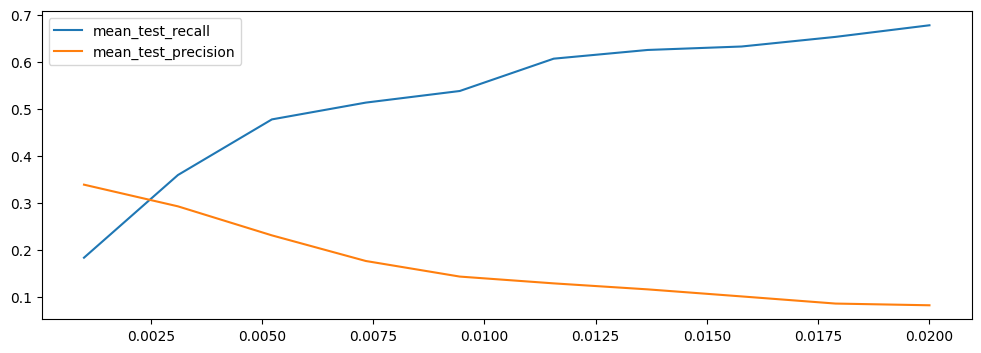

In [83]:
plt.figure(figsize=(12, 4))
df = pd.DataFrame(grid.cv_results_)
for score in ['mean_test_recall', 'mean_test_precision']:
    plt.plot(df['param_contamination'], df[score], label=score)

plt.legend()